In [4]:
from pathlib import Path
import anndata as ad

data_dir = Path("/work/magroup/skrieger/Syndri/data/xenium_noise_experiment")
files = sorted(data_dir.glob("GSM950*_1pct.h5ad"))

In [5]:
filepath = [str(f) for f in list(files) if "B4" in str(f)][0]

adata = ad.read_h5ad(filepath)

In [6]:
from sklearn.decomposition import PCA
import numpy as np

prob_layer = "admix_probs_optimized_unexpressedgenes_withquerycelltype_X"

# Probability percentiles to evaluate
percentiles = [50, 60, 70, 80, 90]

# Original expression
X_raw = adata.X.toarray().copy()

# Admixture probabilities
probs = adata.layers[prob_layer].toarray()

# Percentiles are defined over all nonzero predicted probabilities
nonzero_probs = probs[probs > 0]

# Mask of originally expressed gene-cell entries
expressed_mask = X_raw > 0

threshold_info = {}


# --------------------------------------------------
# Raw PCA
# --------------------------------------------------

X = X_raw.copy()

X = (
    (X - np.mean(X, axis=0))
    / (np.std(X, axis=0) + np.finfo(float).eps)
)

adata.obsm["X_pca_prob_raw"] = PCA(
    n_components=30,
    random_state=42
).fit_transform(X)

threshold_info["raw"] = {
    "percentile": None,
    "threshold": None,
    "fraction_expressed_removed": 0.0,
}

print(" raw | no transcript removal")


# --------------------------------------------------
# Cleaned PCAs
# --------------------------------------------------

for percentile in percentiles:

    name = f"p{percentile}"

    # Probability threshold
    threshold = np.percentile(
        nonzero_probs,
        percentile
    )

    # Only count entries that were actually expressed
    removal_mask = (
        expressed_mask
        & (probs > threshold)
    )

    # Clean expression matrix
    X = X_raw.copy()
    X[removal_mask] = 0

    # Fraction of originally expressed entries removed
    fraction_expressed_removed = (
        removal_mask.sum()
        / expressed_mask.sum()
    )

    # Standardize genes independently for this condition
    X = (
        (X - np.mean(X, axis=0))
        / (np.std(X, axis=0) + np.finfo(float).eps)
    )

    # PCA
    adata.obsm[f"X_pca_prob_{name}"] = PCA(
        n_components=30,
        random_state=42
    ).fit_transform(X)

    # Store threshold information
    threshold_info[name] = {
        "percentile": percentile,
        "threshold": threshold,
        "fraction_expressed_removed": fraction_expressed_removed,
    }

    print(
        f"{name:>4} | "
        f"threshold = {threshold:.4f} | "
        f"expressed entries removed = "
        f"{fraction_expressed_removed:.2%}"
    )

 raw | no transcript removal
 p50 | threshold = 0.8762 | expressed entries removed = 50.00%
 p60 | threshold = 0.9323 | expressed entries removed = 40.00%
 p70 | threshold = 0.9674 | expressed entries removed = 30.00%
 p80 | threshold = 0.9875 | expressed entries removed = 20.00%
 p90 | threshold = 0.9970 | expressed entries removed = 10.00%


In [7]:
import numpy as np
import pandas as pd
from sklearn.neighbors import NearestNeighbors


def t_lineage_cohesion(
    embedding,
    labels,
    t_subtypes,
    k=15,
):
    labels = np.asarray(labels)
    results = []

    t_mask = np.isin(labels, t_subtypes)
    non_t_mask = ~t_mask

    for subtype in t_subtypes:

        query_idx = np.where(labels == subtype)[0]

        # Other T-cell subtypes
        other_t_idx = np.where(
            t_mask & (labels != subtype)
        )[0]

        non_t_idx = np.where(non_t_mask)[0]

        if (
            len(query_idx) == 0
            or len(other_t_idx) < k
            or len(non_t_idx) < k
        ):
            continue

        X_query = embedding[query_idx]

        # k nearest cells from OTHER T subtypes
        nn_t = NearestNeighbors(
            n_neighbors=k
        ).fit(embedding[other_t_idx])

        d_t, _ = nn_t.kneighbors(X_query)

        # k nearest NON-T cells
        nn_other = NearestNeighbors(
            n_neighbors=k
        ).fit(embedding[non_t_idx])

        d_other, _ = nn_other.kneighbors(X_query)

        d_t = np.median(d_t, axis=1)
        d_other = np.median(d_other, axis=1)

        cohesion = (
            (d_other - d_t)
            / (d_other + d_t + 1e-12)
        )

        for j, cell_idx in enumerate(query_idx):
            results.append({
                "cell": cell_idx,
                "t_subtype": subtype,
                "d_other_t": d_t[j],
                "d_non_t": d_other[j],
                "t_lineage_cohesion": cohesion[j],
                "other_t_closer": d_t[j] < d_other[j],
            })

    return pd.DataFrame(results)

In [8]:
adata.obs['harmony_cell_type'].unique()

['fibroblast of breast', 'classical monocyte', 'fibroblast of lung', 'smooth muscle cell', 'plasmacytoid dendritic cell', ..., 'cytotoxic T cell', 'plasma cell', 'macrophage', 'natural T-regulatory cell', 'mast cell']
Length: 15
Categories (15, object): ['CD4-positive, alpha-beta memory T cell', 'capillary endothelial cell', 'classical monocyte', 'cytotoxic T cell', ..., 'pericyte', 'plasma cell', 'plasmacytoid dendritic cell', 'smooth muscle cell']

In [9]:
t_subtypes = [
    "CD4-positive, alpha-beta memory T cell",
    "natural T-regulatory cell",
    "cytotoxic T cell",
    "natural killer cell",
]

t_df = t_lineage_cohesion(
    adata.obsm["X_pca_prob_p50"],
    adata.obs["harmony_cell_type"],
    t_subtypes,
    k=15,
)

t_df.groupby("t_subtype").agg(
    median_cohesion=("t_lineage_cohesion", "median"),
    fraction_other_t_closer=("other_t_closer", "mean"),
)

,median_cohesion,fraction_other_t_closer
t_subtype,,
"CD4-positive, alpha-beta memory T cell",0.238562,0.915152
cytotoxic T cell,0.153458,0.883352
natural T-regulatory cell,0.220603,0.982201
natural killer cell,0.173026,0.953642


In [10]:
conditions = [
    "raw",
    "p50",
    "p60",
    "p70",
    "p80",
    "p90",
]

all_t_cohesion = []

for condition in conditions:

    df = t_lineage_cohesion(
        adata.obsm[f"X_pca_prob_{condition}"],
        adata.obs["harmony_cell_type"],
        t_subtypes,
        k=15,
    )

    df["condition"] = condition

    if condition == "raw":
        df["fraction_removed"] = 0
    else:
        df["fraction_removed"] = (
            threshold_info[condition][
                "fraction_expressed_removed"
            ]
        )

    all_t_cohesion.append(df)

t_cohesion_df = pd.concat(
    all_t_cohesion,
    ignore_index=True
)

In [11]:
t_summary = (
    t_cohesion_df
    .groupby(
        ["condition", "fraction_removed", "t_subtype"],
        as_index=False
    )
    .agg(
        median_cohesion=("t_lineage_cohesion", "median"),
        fraction_other_t_closer=("other_t_closer", "mean"),
    )
)

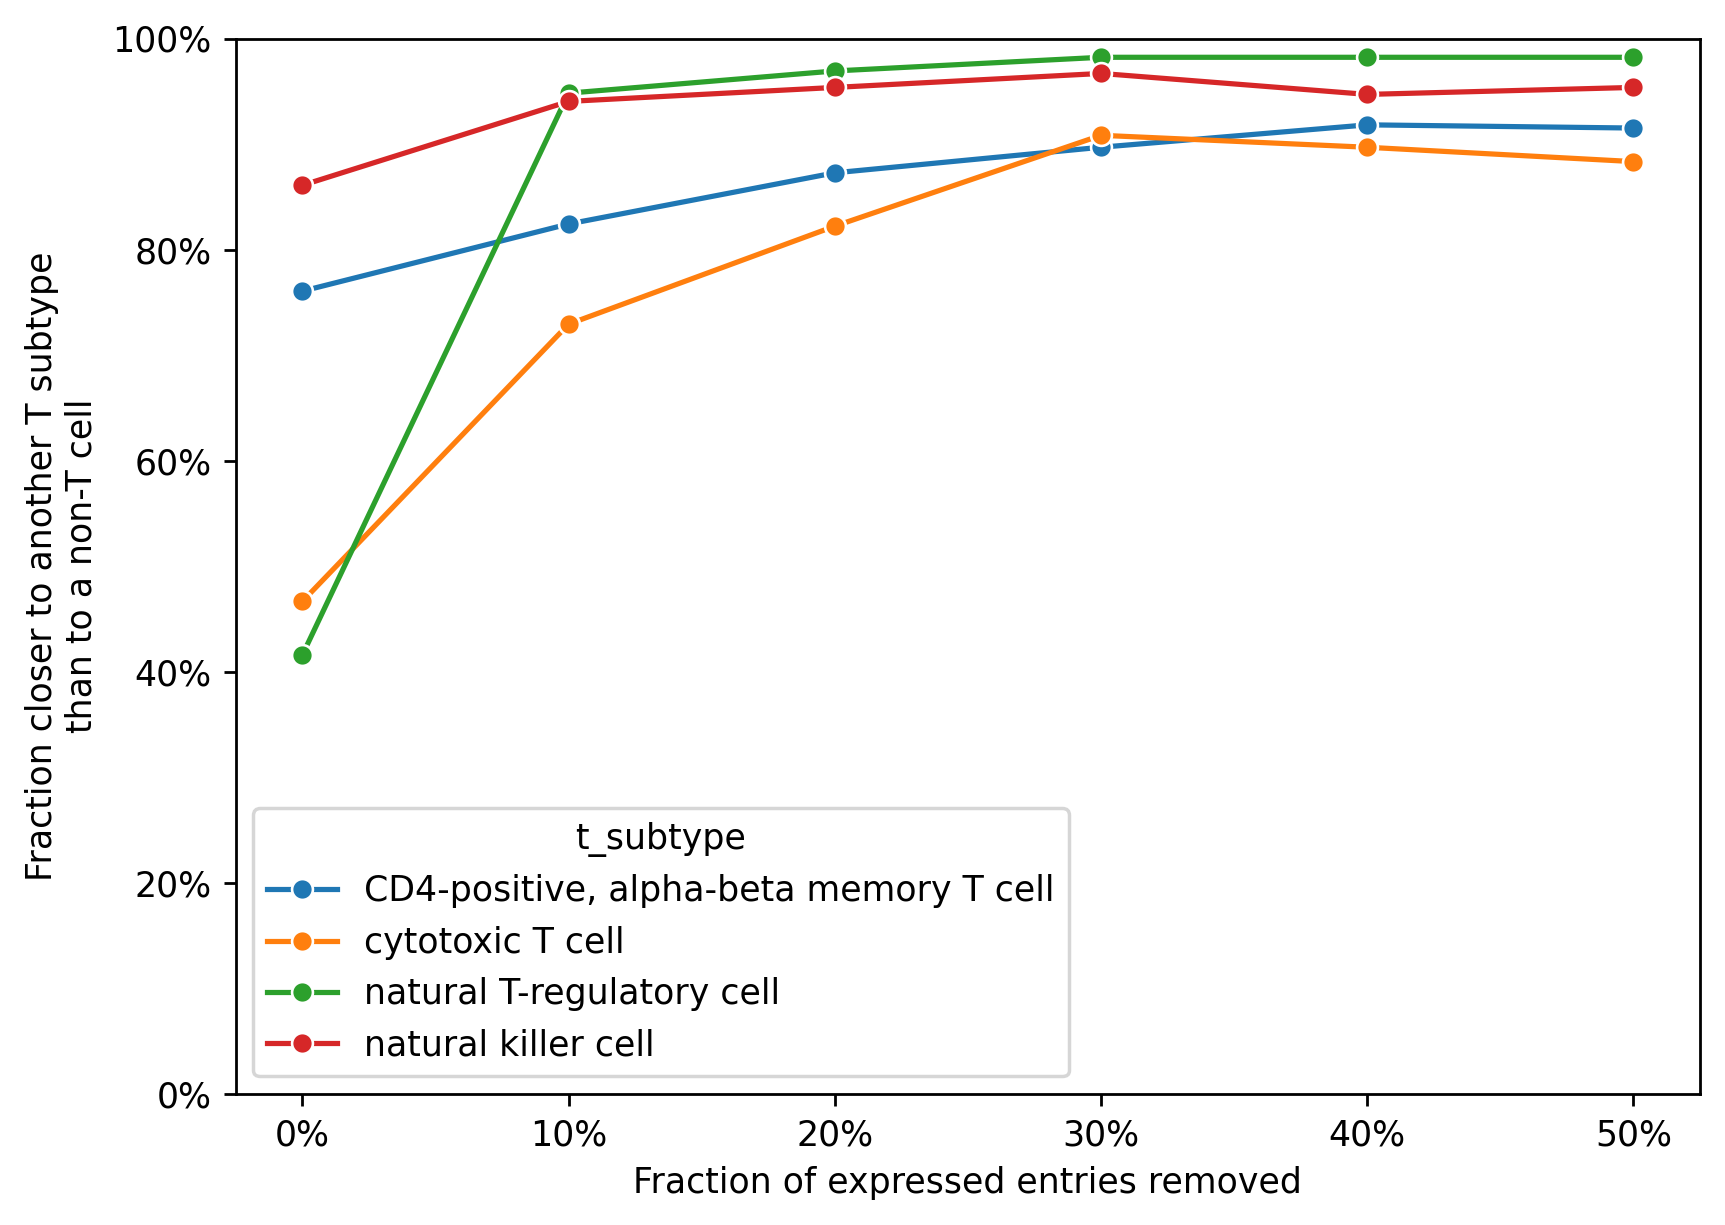

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

fig, ax = plt.subplots(figsize=(7, 5), dpi=250)

sns.lineplot(
    data=t_summary,
    x="fraction_removed",
    y="fraction_other_t_closer",
    hue="t_subtype",
    marker="o",
    ax=ax,
)

ax.set_xlabel("Fraction of expressed entries removed")
ax.set_ylabel(
    "Fraction closer to another T subtype\n"
    "than to a non-T cell"
)

ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.set_ylim(0, 1)

plt.tight_layout()